In [5]:
import sys
sys.path.append('..')

import os
import gc
import h5py
import joblib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectFromModel
from xgboost import XGBClassifier
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout
from src.data.loader import GliomaDataLoader

MODEL_DIR = "../results/models/ramanspy_baselines"
os.makedirs(MODEL_DIR, exist_ok=True)
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

In [6]:
DATA_PATH = "../data/processed/RamanSPy_glioma_dataset.h5"
SPLIT_FILE = "../data/splits/ramanspy_splits.json"
N_FEATURES = 570

print(" Initializăm DataLoader-ul...")
loader = GliomaDataLoader(
    data_path=DATA_PATH,
    split_file=SPLIT_FILE,
    memory_mapped=False,
    tumor_only=True  # MAGIC FLAG: Păstrează doar cei 115k pixeli de tumoră reală
)

print(f" Setup complet! Datele sunt gata pentru antrenament.")

📂 Initializăm DataLoader-ul...
📂 Loading data from ..\data\processed\RamanSPy_glioma_dataset.h5...
🔬 'tumor_only=True': Filtering out healthy tissue...
   ✅ Filtered to 115278 Pure Tumor Spectra.
✅ Setup complet! Datele sunt gata pentru antrenament.


In [ ]:
def build_1d_cnn(input_shape, num_classes=6):
    model = Sequential([
        Conv1D(32, kernel_size=3, activation='relu', input_shape=input_shape),
        MaxPooling1D(pool_size=2),
        Conv1D(64, kernel_size=3, activation='relu'),
        MaxPooling1D(pool_size=2),
        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

print(f" Pornim antrenamentul Multi-Model TRTR pe {N_FEATURES} features...")

for fold_data in loader:
    fold_name = fold_data['fold_name']
    print(f"\n========================================")
    print(f" Procesăm {fold_name}")
    print(f"========================================")
    
    X_train, y_train = fold_data['train']
    X_train = X_train.astype(np.float32)
    
    if np.min(y_train) == 1: y_train = y_train - 1 # Fix indexare
        
    print("  [Apollo] Antrenăm SVM + RF Selector...")
    apollo = Pipeline([
        ('selector', SelectFromModel(RandomForestClassifier(n_estimators=50, random_state=42), max_features=20)),
        ('svm', SVC(kernel='rbf', probability=True, random_state=42))
    ])
    apollo.fit(X_train, y_train)
    joblib.dump(apollo, f"{MODEL_DIR}/apollo_{fold_name}.joblib")
    
    print("  [RF] Antrenăm Random Forest...")
    rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    joblib.dump(rf, f"{MODEL_DIR}/rf_{fold_name}.joblib")
    
    print("  [XGB] Antrenăm XGBoost...")
    xgb = XGBClassifier(n_estimators=300, random_state=42, n_jobs=-1)
    xgb.fit(X_train, y_train)
    xgb.save_model(f"{MODEL_DIR}/xgb_{fold_name}.json")
    
    print("  [CNN] Antrenăm 1D-CNN...")
    cnn = build_1d_cnn((N_FEATURES, 1), num_classes=6)
    cnn.fit(X_train.reshape(-1, N_FEATURES, 1), y_train, epochs=10, batch_size=64, verbose=0)
    cnn.save(f"{MODEL_DIR}/cnn_{fold_name}.keras")
    
    del apollo, rf, xgb, cnn, X_train, y_train; gc.collect()

print("\n Antrenament complet!")

In [7]:
binary_results = {'Apollo': [], 'RF_Standard': [], 'XGBoost': [], '1D_CNN': []}
print(" Testăm modelele pe task-ul binar (Mutant vs. Wildtype)...")

for fold_data in loader:
    fold_name = fold_data['fold_name']
    X_val = fold_data['val'][0].astype(np.float32)
    y_val_6 = fold_data['val'][1]
    
    if np.min(y_val_6) == 1: y_val_6 -= 1
    y_val_bin = np.where(y_val_6 < 3, 0, 1) # Binarizare
    
    # Incarcare si testare rapida
    apollo = joblib.load(f"{MODEL_DIR}/apollo_{fold_name}.joblib")
    binary_results['Apollo'].append(accuracy_score(y_val_bin, np.where(apollo.predict(X_val) < 3, 0, 1)))
    
    rf = joblib.load(f"{MODEL_DIR}/rf_{fold_name}.joblib")
    binary_results['RF_Standard'].append(accuracy_score(y_val_bin, np.where(rf.predict(X_val) < 3, 0, 1)))
    
    xgb_m = XGBClassifier()
    xgb_m.load_model(f"{MODEL_DIR}/xgb_{fold_name}.json")
    binary_results['XGBoost'].append(accuracy_score(y_val_bin, np.where(xgb_m.predict(X_val) < 3, 0, 1)))
    
    cnn = tf.keras.models.load_model(f"{MODEL_DIR}/cnn_{fold_name}.keras")
    cnn_preds = np.argmax(cnn.predict(X_val.reshape(-1, N_FEATURES, 1), verbose=0), axis=1)
    binary_results['1D_CNN'].append(accuracy_score(y_val_bin, np.where(cnn_preds < 3, 0, 1)))
    
    del apollo, rf, xgb_m, cnn; gc.collect()

# Tabelul glorioaselor rezultate
print("\n === FINAL SHOWDOWN: RAMANSPY VS LEGACY (BINARY TASK) ===")
legacy_scores = {'Apollo': 0.6666, 'RF_Standard': 0.6604, 'XGBoost': 0.7135, '1D_CNN': 0.4384}

for model_name in binary_results.keys():
    new_acc = np.mean(binary_results[model_name])
    leg_acc = legacy_scores[model_name]
    diff = (new_acc - leg_acc) * 100
    
    print(f"\n{model_name}:")
    print(f"  Legacy Baseline: {leg_acc:.4f}")
    print(f"  RamanSPy Score:  {new_acc:.4f}")
    if diff > 0: print(f"   RamanSPy WINS by +{diff:.2f}%")
    else: print(f"   Legacy wins by {abs(diff):.2f}%")

🔍 Testăm modelele pe task-ul binar (Mutant vs. Wildtype)...

🏆 === FINAL SHOWDOWN: RAMANSPY VS LEGACY (BINARY TASK) ===

Apollo:
  Legacy Baseline: 0.6666
  RamanSPy Score:  0.6688
  ✅ RamanSPy WINS by +0.22%

RF_Standard:
  Legacy Baseline: 0.6604
  RamanSPy Score:  0.6286
  ❌ Legacy wins by 3.18%

XGBoost:
  Legacy Baseline: 0.7135
  RamanSPy Score:  0.5920
  ❌ Legacy wins by 12.15%

1D_CNN:
  Legacy Baseline: 0.4384
  RamanSPy Score:  0.6900
  ✅ RamanSPy WINS by +25.16%


📊 Generăm graficele pentru secțiunea de Metodologie...


C:\Users\iulia\AppData\Local\Temp\ipykernel_18300\381300656.py:29: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\iulia\anaconda3\envs\glioma\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


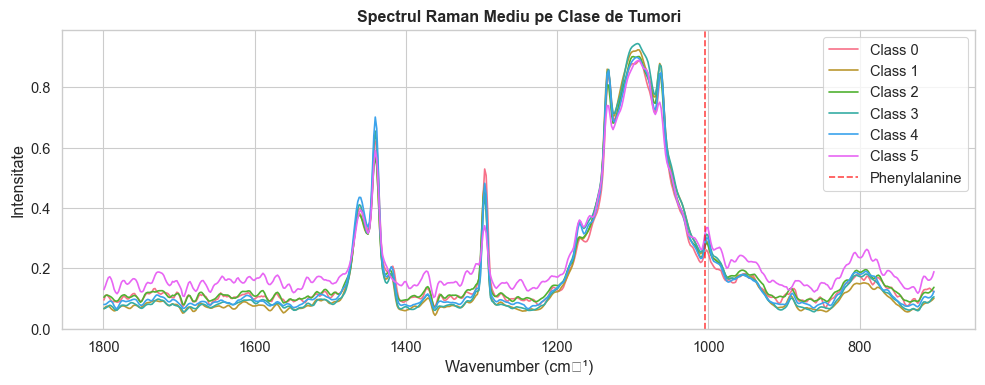

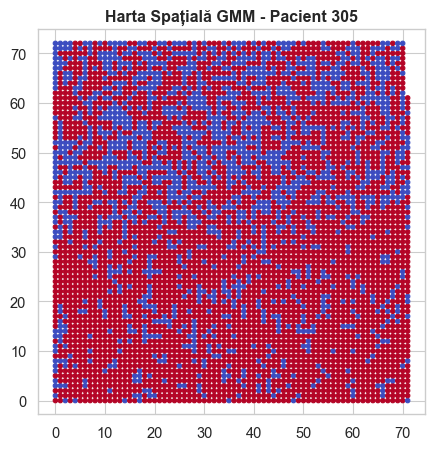

In [8]:
print(" Generăm graficele pentru secțiunea de Metodologie...")

with h5py.File(DATA_PATH, 'r') as f:
    X_viz = f['spectra_smoothed'][:] 
    y_class_viz = f['y_class'][:]
    y_tumor_viz = f['y_tumor'][:]
    wn_viz = f['wavenumbers'][:]
    coords_viz = f['coords'][:]
    samples_viz = f['sample_ids'][:]
    if isinstance(samples_viz[0], (bytes, np.bytes_)):
        samples_viz = np.char.decode(samples_viz.astype('S'), 'utf-8')

# Plot 1: Spectrul Mediu (Peak-urile Chimice)
tumor_mask = (y_tumor_viz == 1)
X_tumor = X_viz[tumor_mask]
y_t_class = y_class_viz[tumor_mask]

fig, ax = plt.subplots(figsize=(10, 4))
colors = sns.color_palette("husl", len(np.unique(y_t_class)))
for i, c in enumerate(np.unique(y_t_class)):
    ax.plot(wn_viz, np.mean(X_tumor[y_t_class == c], axis=0), label=f'Class {c}', color=colors[i])

ax.axvline(x=1004, color='red', linestyle='--', alpha=0.7, label='Phenylalanine')
ax.set_title("Spectrul Raman Mediu pe Clase de Tumori", fontweight='bold')
ax.set_xlabel("Wavenumber (cm⁻¹)")
ax.set_ylabel("Intensitate")
ax.invert_xaxis()
ax.legend()
plt.tight_layout()
plt.show()

# Plot 2: Harta Spațială a Tumorii
sample_id = np.unique(samples_viz)[0]
mask = (samples_viz == sample_id)

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(coords_viz[mask, 0], coords_viz[mask, 1], c=y_tumor_viz[mask], cmap='coolwarm', s=10)
ax.set_title(f"Harta Spațială GMM - Pacient {sample_id}", fontweight='bold')
plt.axis('equal')
plt.show()